# Q3: Were editors' winning picks actually better?
For each test with a recorded winner, compare the chosen arm with the best alternative.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from google.cloud import bigquery

sys.path.append(str(Path("..").resolve()))
from src.stats.decisions import CATEGORY_ORDER, add_decision_columns
from src.stats.srm import reliable_test_ids

load_dotenv(Path("..") / ".env")
client = bigquery.Client(project=os.environ["GCP_PROJECT_ID"], location="asia-northeast1")

ALPHA = 0.05

In [2]:
balance = client.query("""
    select test_id, started_at, chi_square_stat, degrees_of_freedom
    from `headline-ab-audit.analytics_marts.fct_test_balance`
    where dataset_split = 'exploratory'
""").to_dataframe()
balance["started_at"] = balance["started_at"].dt.tz_localize(None)

reliable_ids = reliable_test_ids(balance, "after window")
reliable_before_ids = reliable_test_ids(balance, "before window")

print(f"Reliable tests after the window: {len(reliable_ids)}")
print(f"Reliable tests before the window: {len(reliable_before_ids)}")

c:\dev\headline-ab-audit\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Reliable tests after the window: 3472
Reliable tests before the window: 333


In [3]:
decisions = add_decision_columns(
    client.query("""
        select *
        from `headline-ab-audit.analytics_marts.fct_editor_decisions`
        where dataset_split = 'exploratory'
    """).to_dataframe()
)
print(f"Tests with exactly one winner: {len(decisions)}")

c:\dev\headline-ab-audit\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Tests with exactly one winner: 1150


In [4]:
primary = decisions[decisions["test_id"].isin(reliable_ids)]
before = decisions[decisions["test_id"].isin(reliable_before_ids)]

summary = pd.DataFrame({
    "primary (after window)": primary["category"].value_counts(normalize=True),
    "sensitivity (before window)": before["category"].value_counts(normalize=True),
}).reindex(CATEGORY_ORDER).fillna(0)

print(f"Primary sample: {len(primary)} tests, sensitivity sample: {len(before)} tests")
summary.style.format("{:.1%}")

Primary sample: 730 tests, sensitivity sample: 157 tests


,primary (after window),sensitivity (before window)
category,,
"Top arm, clearly better",7.1%,10.8%
"Top arm, not distinguishable",63.0%,72.6%
"Non-top arm, not distinguishable",29.5%,16.6%
"Non-top arm, significantly worse",0.4%,0.0%


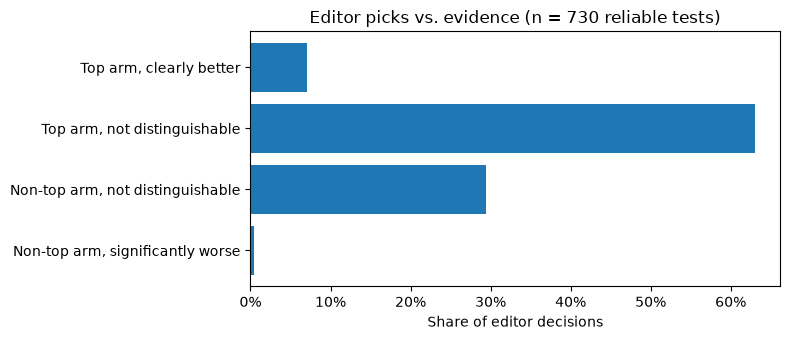

In [5]:
order = CATEGORY_ORDER
shares = primary["category"].value_counts(normalize=True).reindex(order).fillna(0)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(order[::-1], shares[order[::-1]])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Share of editor decisions")
ax.set_title(f"Editor picks vs. evidence (n = {len(primary)} reliable tests)")
fig.tight_layout()

Path("../docs/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../docs/figures/q3_editor_decisions.png", dpi=150)
plt.show()

In [6]:
non_top = primary[~primary["winner_is_top"]]
relative_loss = (non_top["top_ctr"] - non_top["winner_ctr"]) / non_top["top_ctr"]

print(f"Non-top picks: {len(non_top)} of {len(primary)}")
print(f"Median relative CTR loss vs. top arm: {relative_loss.median():.1%}")

Non-top picks: 218 of 730
Median relative CTR loss vs. top arm: 7.1%


In [7]:
export = pd.concat([
    primary.assign(sample="after window (primary)"),
    before.assign(sample="before window (sensitivity)"),
])[[
    "test_id",
    "started_at",
    "sample",
    "n_arms",
    "category",
    "winner_is_top",
    "p_value",
    "within_noise",
    "winner_ctr",
    "top_ctr",
]].copy()
export["within_noise_flag"] = export["within_noise"].astype(int)

dataset = bigquery.Dataset(f"{client.project}.analysis")
dataset.location = "asia-northeast1"
client.create_dataset(dataset, exists_ok=True)

job_config = bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE")
client.load_table_from_dataframe(
    export, f"{client.project}.analysis.editor_decisions", job_config=job_config
).result()
print(f"Uploaded {len(export)} rows to analysis.editor_decisions")

Uploaded 887 rows to analysis.editor_decisions


## Q3 findings

**Sample:** 1,150 tests recorded exactly one editor-selected winner. Of these, 730 started
after the flagged window and passed the SRM check (primary sample); 157 started before the
window (sensitivity check).

1. **Editors picked the top-CTR arm in 70.1% of tests, but only 7.1% of all picks were
   clearly better than the runner-up** at p < 0.05. In 63.0% of tests, the pick matched
   the top arm while the difference was within noise.

2. **92.5% of decisions were made when the data could not separate the chosen arm from
   the best alternative** (63.0% top arm within noise + 29.5% non-top arm within noise).
   Only 0.4% of picks were significantly worse than the top arm.

3. **When editors did not pick the top arm (218 tests, 29.9%), the median relative CTR loss
   was 7.1%.** This is far below the minimum detectable effect in Q2 (about 21% for the
   largest reliable two-arm test), so these differences could not have been detected.

4. **The pattern holds before the window:** 89.2% of decisions were within noise, and
   10.8% were clearly better. Editors picked the top arm more often before the window
   (83.4% vs. 70.1%); the data does not show why.

**Implication:** almost every decision was made before the test had enough data.
A minimum sample size rule, based on the effect size worth detecting, would have marked
most of these tests as inconclusive rather than producing a "winner".

**Limitations:**
- Only 21% of reliable tests after the window (730 of 3,472) recorded a winner, and these
  may differ from tests without one.
- Ranking arms by CTR and then comparing the top arm with the runner-up favours the top arm
  (winner's curse), so the 7.1% share of clearly better picks is likely overstated.
- Each pick is compared with one alternative only, with no correction for multiple arms.